# Example of the aitlas toolbox in the context of change detection

## Import the required packages

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import DSIFNDataset
from aitlas.utils import image_loader
from aitlas.models import UnetChangeDetection
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor

## Visualize images and masks

Total number of patches: 3600


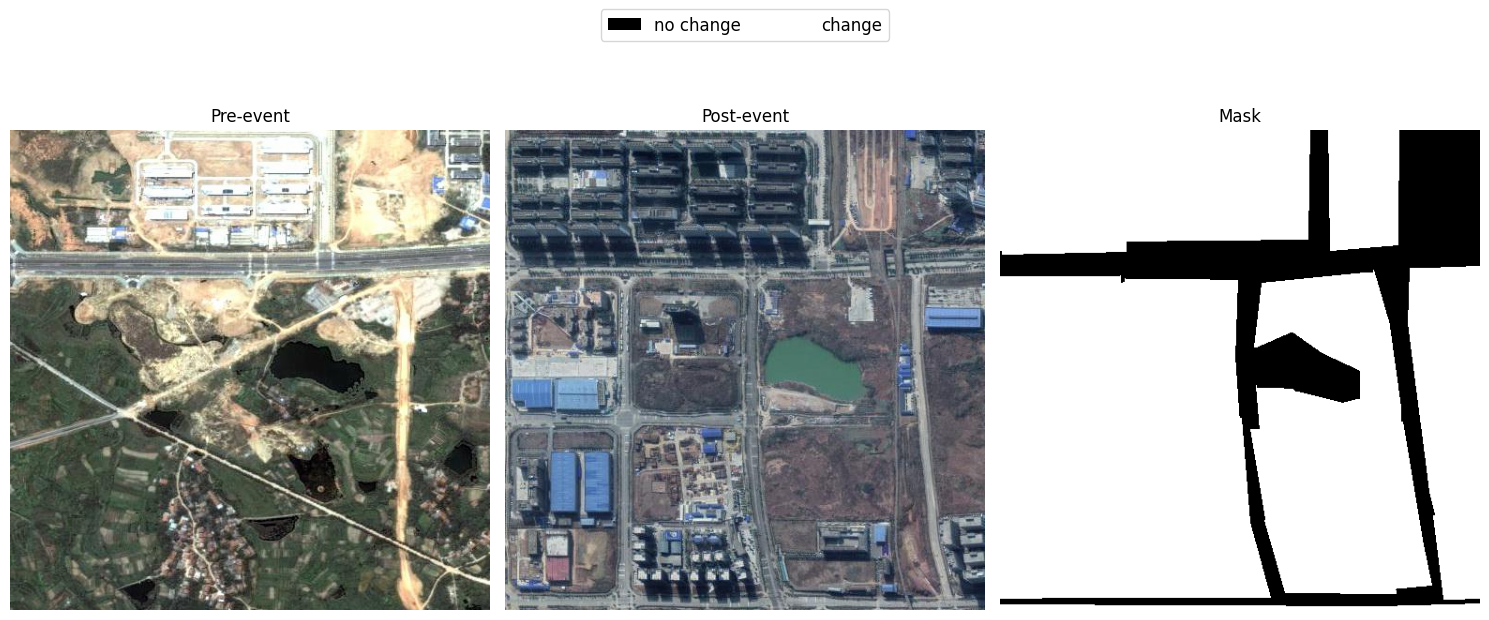

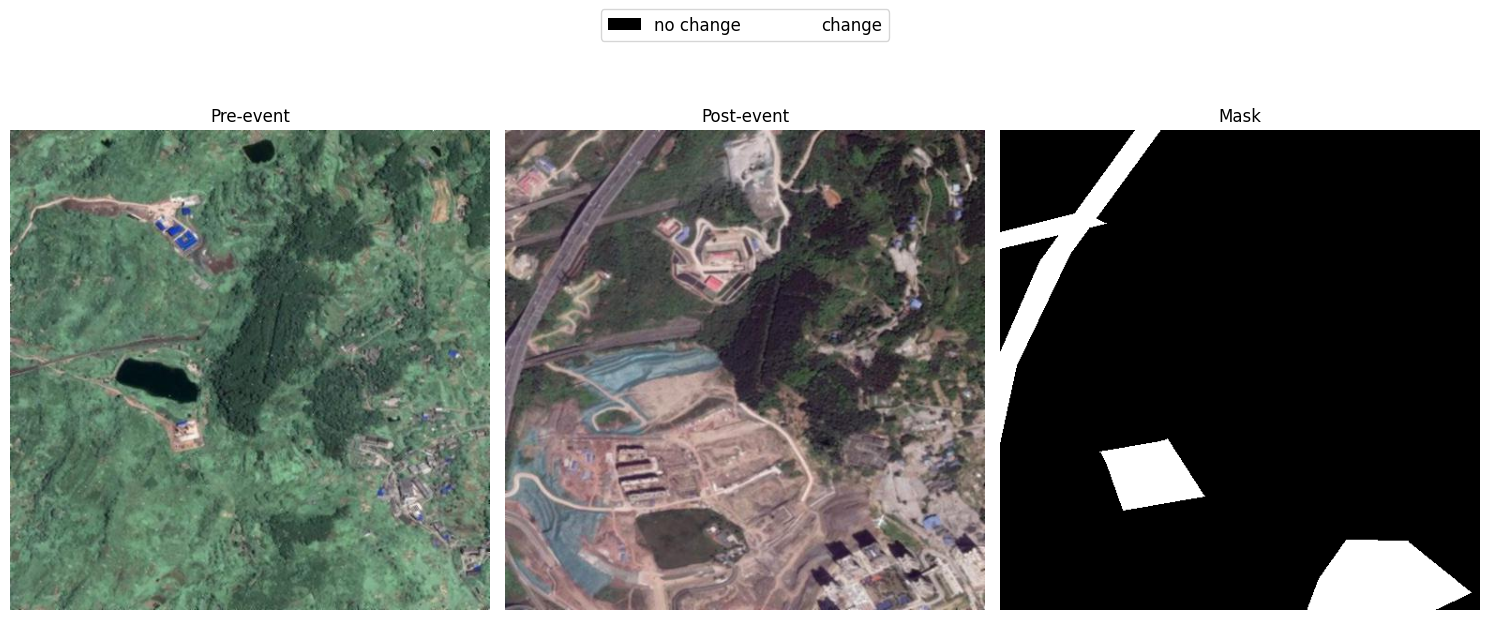

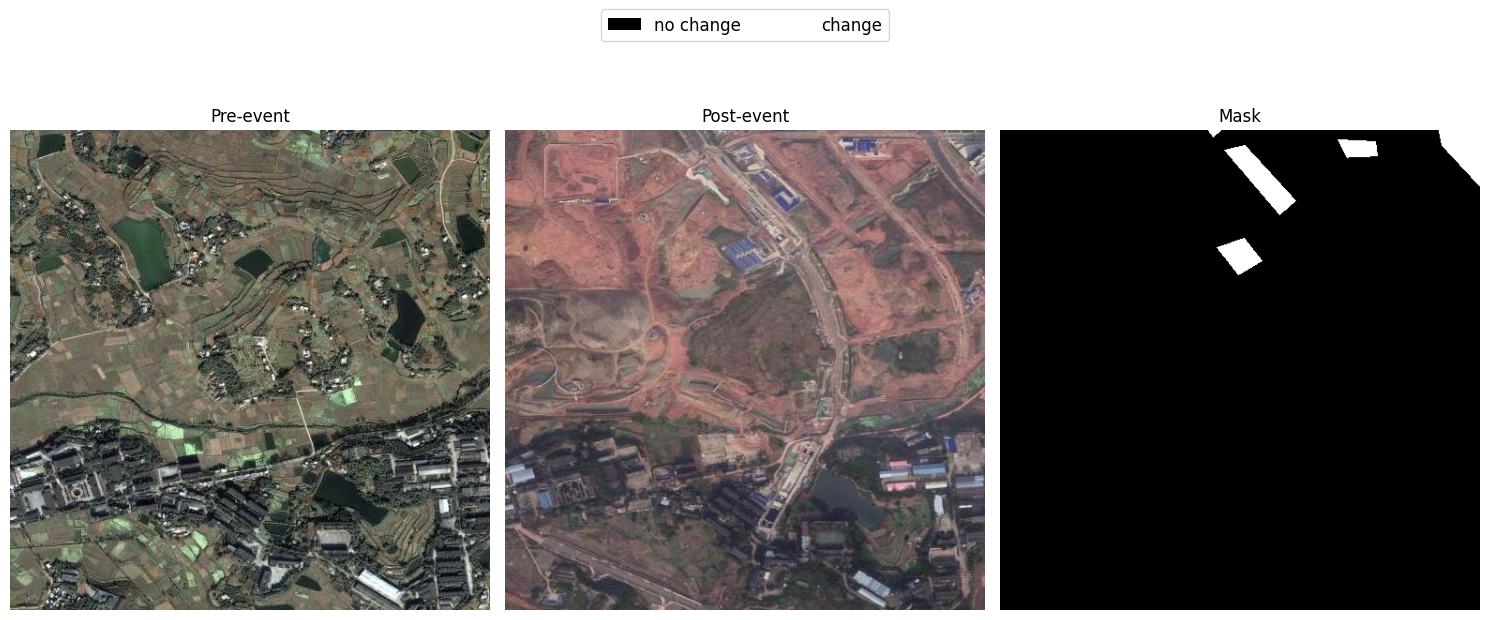

In [ ]:
dataset_config = {
    "data_dir" : "./data/dsifn/train/",
}
dataset = DSIFNDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

dataset.show_image(100);
dataset.show_image(15);
dataset.show_image(22);

In [20]:
dataset.data_distribution_table()

,Number of pixels
no change,610836094.0
change,332882306.0


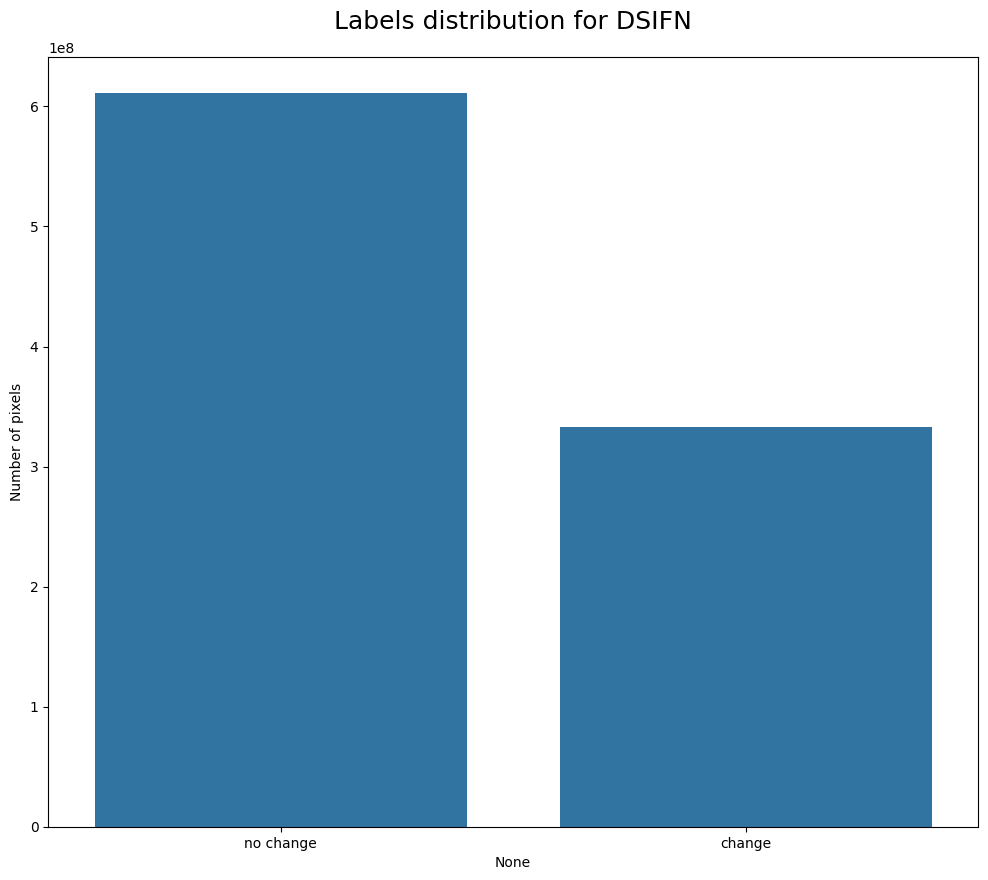

In [21]:
dataset.data_distribution_barchart();

## Load training and test data

New 60/20/20 train/val/test splits

In [ ]:
train_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "./data/dsifn/",
    "csv_file" : "./data/dsifn/dsifn_train.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = DSIFNDataset(train_dataset_config)

test_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "./data/dsifn/",
    "csv_file" : "./data/dsifn/dsifn_val.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
test_dataset = DSIFNDataset(test_dataset_config)
len(train_dataset), len(test_dataset)

(2188, 730)

Original train/val/test splits

In [ ]:
train_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "./data/dsifn/train/",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = DSIFNDataset(train_dataset_config)

test_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "./data/dsifn/val/",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
test_dataset = DSIFNDataset(test_dataset_config)
len(train_dataset), len(test_dataset)

(3600, 340)

## Create the model

In [ ]:
epochs = 50
model_directory = "./data/experiments/dsifn"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": False, 
    "threshold": 0.5,
    "metrics": ["accuracy", "precision", "recall", "f1_score", "iou"]
}

model = UnetChangeDetection(model_config)
model.prepare()

## Start the training

In [7]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1',
)

model_path = model_directory + "/checkpoint.pth.tar"
model.load_model(model_path)
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
test_metrics = model.running_metrics.get_scores(model.metrics)

2026-01-28 09:48:28,919 INFO Starting training.
training: 100%|██████████| 225/225 [00:29<00:00,  7.60it/s]
2026-01-28 09:48:58,607 INFO epoch: 1, loss:  0.27655
testing on train set: 100%|██████████| 225/225 [00:15<00:00, 14.12it/s]
2026-01-28 09:49:15,797 INFO Accuracy:0.6479715728759765, Accuracy per Class:[0.63408975 0.6618534 ], Precision Micro:0.6282650575753559, Precision Macro:0.5745631610343924, Precision Weighted:0.5928049698938783, Precision per Class:[0.63489479 0.51423154], Recall Micro:0.6789803646971103, Recall Macro:0.5416693716887466, Recall Weighted:0.6789803646971103, Recall per Class:[0.99580172 0.08753702], F1_score Micro:0.6526389469812268, F1_score Macro:0.4625084211892475, F1_score Weighted:0.5571170719521723, F1_score per Class:[0.77541016 0.14960668], IOU:0.48438311729360506, IOU mean:0.3570255925102274, IOU per Class:[0.6331999  0.08085129]
training: 100%|██████████| 225/225 [00:28<00:00,  7.87it/s]
2026-01-28 09:49:44,396 INFO epoch: 2, loss:  0.27107
testin

## Predictions

2026-01-28 10:36:57,162 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/dsifn/checkpoint.pth.tar
2026-01-28 10:36:57,490 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/dsifn/checkpoint.pth.tar at epoch 51


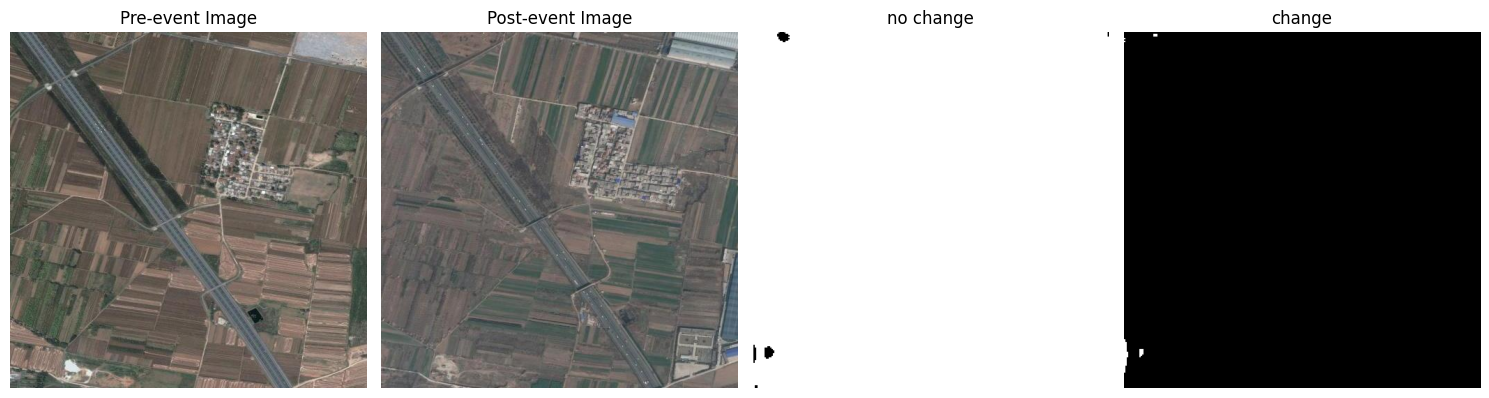

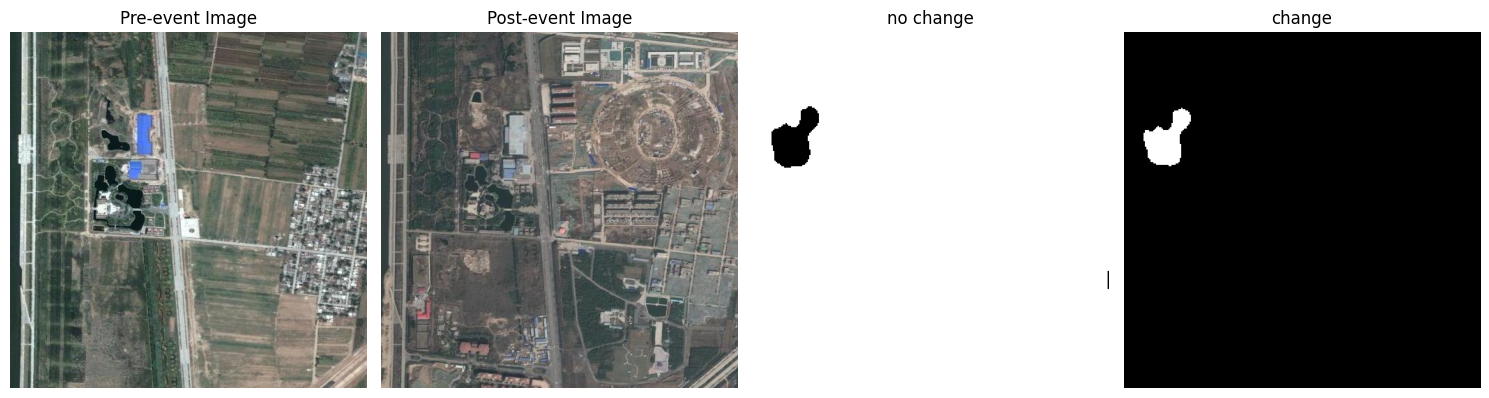

In [ ]:
model_path = "./data/experiments/dsifn/checkpoint.pth.tar"
labels = ["no change","change"]
transform = ResizeToTensor()
model.load_model(model_path)

image1 = image_loader("./data/dsifn/test/t1/46.jpg")
image2 = image_loader("./data/dsifn/test/t2/46.jpg")
fig = model.predict_masks(image1, image2, labels, transform)

image1 = image_loader("./data/dsifn/test/t1/8.jpg")
image2 = image_loader("./data/dsifn/test/t2/8.jpg")
fig = model.predict_masks(image1, image2, labels, transform)